# Representation model -> clustering

Train (or load) a representation model, embed a subsample of paintings, cluster them and compare the clusters with metadata.

**All parameters are in the Config cell.** Change them there and use *Run All*.
Clustering, the silhouette score, NMI/AMI and the sample grid all use the **same** paintings (`N_CLUSTER` paintings from `CLUSTER_SPLIT`).

In [1]:
import dataclasses
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_mutual_info_score, normalized_mutual_info_score, silhouette_score, adjusted_rand_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer, StandardScaler
from torch.utils.data import DataLoader, Subset

if "google.colab" in sys.modules:
    SRC = Path("/content/Project/src")          # or /content/drive/MyDrive/.../Project/src
else:
    SRC = Path.cwd().parents[1]                 # training/ -> restore_pipeline/ -> src/

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from restore_pipeline.dataprocessing.dataloading import (
    BASIC_TRANSFORM, RESIZE_128, SOBEL_TRANSFORM, DataConfig,
    get_damaged_splits_dataloaders, get_splits, get_splits_dataloaders,
)
from restore_pipeline.representation.models import (
    ConvAutoencoder, ConvOnlyAutoencoder, DeepConvOnlyAutoencoder, encode_loader,
)
from restore_pipeline.representation.train import (
    TrainConfig, damaged_reconstruction_loss, fit, load_checkpoint, reconstruction_loss, save_checkpoint,
)
from restore_pipeline.representation.plotting import plot_reconstructions
from restore_pipeline.representation.utils import encode_loader_gram
from restore_pipeline.clustering.plotting import plot_cluster_samples, plot_clusters_2d, plot_kmeans_sweep, umap_project
from restore_pipeline.clustering.utils import kmeans_sweep

# Config

In [2]:
# ---------------- Data ----------------
DATA_DIR    = Path("../data")
TRANSFORM   = BASIC_TRANSFORM          # BASIC_TRANSFORM (256 px) | RESIZE_128 | SOBEL_TRANSFORM
BATCH_SIZE  = 64
NUM_WORKERS = 4
SEED        = 42
MIX_CLEAN   = True                # train/validate on damaged AND clean copies of each painting

# Subsample sizes, in paintings (None = whole split)
N_TRAIN = 20_000
N_VAL   = 2_000

# ---------------- Model / training ----------------
MODEL_CLASS  = ConvOnlyAutoencoder
MODEL_KWARGS = dict(in_channels=3, out_channels=3, latent_channels=8)   # in/out = 2 for SOBEL_TRANSFORM
LOSS_FN      = damaged_reconstruction_loss
TRAIN_CFG    = TrainConfig(epochs=25, lr=1e-3)

CHECKPOINT_DIR = Path("checkpoints")
LOAD_FROM = None                  # e.g. CHECKPOINT_DIR / "deep_conv_only.pt"  -> skips training
SAVE_TO   = CHECKPOINT_DIR / "rgb_conv_only.pt"                  # e.g. CHECKPOINT_DIR / "deep_conv_only.pt"

# ---------------- Clustering + evaluation ----------------
CLUSTER_SPLIT = "train"           # "train" | "val" | "test"
N_CLUSTER     = 20_000            # paintings clustered AND evaluated (None = whole split, needs a lot of RAM)
                                  # train + same size and seed as N_TRAIN -> exactly the training paintings
EMBEDDING     = "flat"            # "flat" (model.encode) | "gram" (Gram matrix of the encoder output)
K_SWEEP       = range(2, 21, 2)
K             = 6
LABEL_COLUMNS = ["style", "genre", "artist"]   # metadata compared with the clusters (NMI / AMI)
SAVE_CLUSTERER = CHECKPOINT_DIR / "rgb_conv_only_kmeans6.joblib"          # e.g. CHECKPOINT_DIR / "deep_conv_only_kmeans6.joblib"

def make_preprocess():
    """Embedding -> clustering features. E.g. add PCA(64, whiten=True, random_state=SEED) before Normalizer."""
    return make_pipeline(
        PCA(512, random_state=SEED),
        Normalizer(norm="l2"),
    )

RUN_NAME = MODEL_CLASS.__name__ if LOAD_FROM is None else Path(LOAD_FROM).stem
device = "cuda" if torch.cuda.is_available() else "cpu"

# Data

In [3]:
data_cfg = DataConfig(
    processed_path=DATA_DIR / "wikiart_train_processed",
    cache_dir=str(DATA_DIR),
    seed=SEED,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    transform_train=TRANSFORM,
    transform_val=TRANSFORM,
    transform_test=TRANSFORM,
    transform_full=TRANSFORM,
)


def sample_indices(n_total: int, n: int | None) -> np.ndarray:
    """`n` random row indices, sorted (rows keep dataset order). All rows if `n` is None."""
    if n is None or n >= n_total:
        return np.arange(n_total)
    return np.sort(np.random.default_rng(SEED).choice(n_total, size=n, replace=False))


def with_damaged_copies(idx: np.ndarray, n_paintings: int) -> np.ndarray:
    """With MIX_CLEAN the dataset is [clean..., damaged...]: keep both copies of each painting."""
    return np.concatenate([idx, idx + n_paintings]) if MIX_CLEAN else idx


def subset_loader(loader: DataLoader, idx: np.ndarray, shuffle: bool) -> DataLoader:
    """Same settings as `loader`, restricted to rows `idx`."""
    return DataLoader(
        Subset(loader.dataset, idx.tolist()),
        batch_size=loader.batch_size,
        shuffle=shuffle,
        num_workers=loader.num_workers,
        pin_memory=loader.pin_memory,
        persistent_workers=loader.num_workers > 0,
        generator=torch.Generator().manual_seed(SEED) if shuffle else None,
    )


train_dmg_full, val_dmg_full, _ = get_damaged_splits_dataloaders(data_cfg, mix=MIX_CLEAN)
copies = 2 if MIX_CLEAN else 1
n_train_paintings = len(train_dmg_full.dataset) // copies
n_val_paintings = len(val_dmg_full.dataset) // copies

train_dmg = subset_loader(train_dmg_full, with_damaged_copies(sample_indices(n_train_paintings, N_TRAIN), n_train_paintings), shuffle=True)
val_dmg = subset_loader(val_dmg_full, with_damaged_copies(sample_indices(n_val_paintings, N_VAL), n_val_paintings), shuffle=False)

print(f"train: {len(train_dmg.dataset)} samples ({len(train_dmg)} batches) | val: {len(val_dmg.dataset)} samples")

train: 40000 samples (625 batches) | val: 4000 samples


# Model

In [4]:
if LOAD_FROM is not None:
    model = load_checkpoint(LOAD_FROM, device)
    history = None
else:
    model = MODEL_CLASS(**MODEL_KWARGS).to(device)
    history = fit(model, train_dmg, val_dmg, TRAIN_CFG, loss_fn=LOSS_FN)
    if SAVE_TO is not None:
        save_checkpoint(model, SAVE_TO, history=history)

if history is not None:
    plt.plot(history["train"], label="train")
    plt.plot(history["val"], label="val")
    plt.xlabel("epoch")
    plt.ylabel("MSE")
    plt.title(RUN_NAME)
    plt.legend()
    plt.show()

Epochs:   0%|          | 0/25 [00:00<?, ?it/s]

Training:   0%|          | 0/625 [00:22<?, ?it/s]

KeyboardInterrupt: 

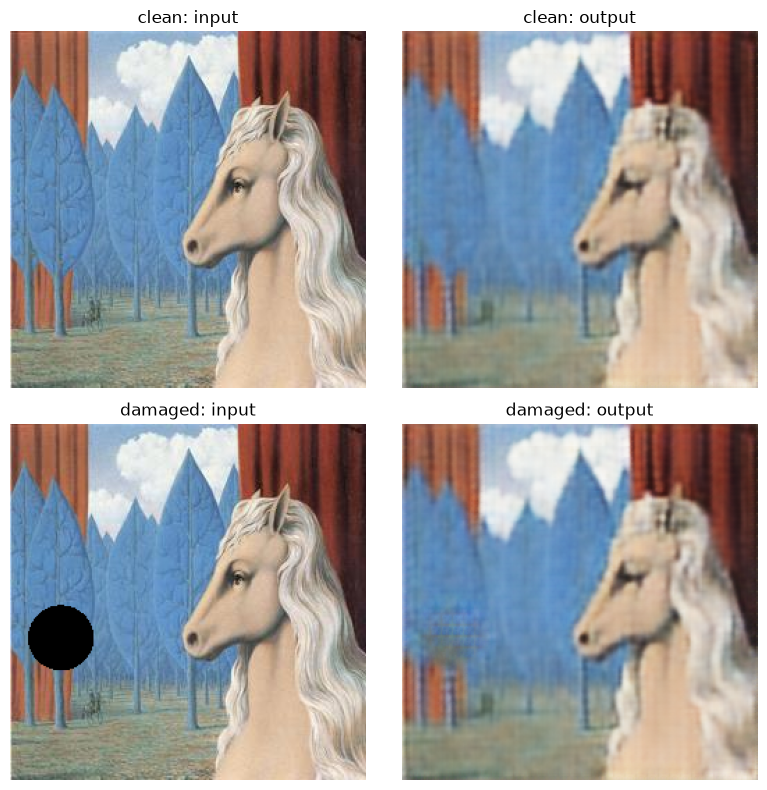

In [ ]:
# One validation painting: clean version and its (fixed) damaged version
i = 1521
offset = n_val_paintings if MIX_CLEAN else 0      # MIX_CLEAN: damaged copies come after the clean ones
sample = val_dmg_full.dataset[i + offset]

plot_reconstructions(model, [sample["target"], sample["image"]], device, titles=["clean", "damaged"])

# Clustering

In [ ]:
# The SAME rows are used for embeddings, metadata, metrics and the sample grid.
splits = dict(zip(["train", "val", "test"], get_splits(data_cfg)))
loaders = dict(zip(["train", "val", "test"], get_splits_dataloaders(dataclasses.replace(data_cfg, shuffle_train=False))))

ds_split = splits[CLUSTER_SPLIT]
cluster_idx = sample_indices(len(ds_split), N_CLUSTER)
cluster_loader = subset_loader(loaders[CLUSTER_SPLIT], cluster_idx, shuffle=False)
ds_cluster = ds_split.select(cluster_idx)                          # images + metadata, same order
meta = ds_cluster.select_columns(LABEL_COLUMNS).to_pandas()

if EMBEDDING == "flat":
    embed = encode_loader(model, cluster_loader, device)
elif EMBEDDING == "gram":
    embed = encode_loader_gram(model.encoder, cluster_loader, device)
else:
    raise ValueError(f"unknown EMBEDDING: {EMBEDDING}")
assert len(embed) == len(meta), "embeddings and metadata are not aligned"

preprocess = make_preprocess()
features = preprocess.fit_transform(embed)
print(f"{CLUSTER_SPLIT}: {len(features)} paintings | embedding {embed.shape[1]} -> features {features.shape[1]}")

train: 10000 paintings | embedding 32768 -> features 512


K-means sweep:   0%|          | 0/10 [00:00<?, ?it/s]

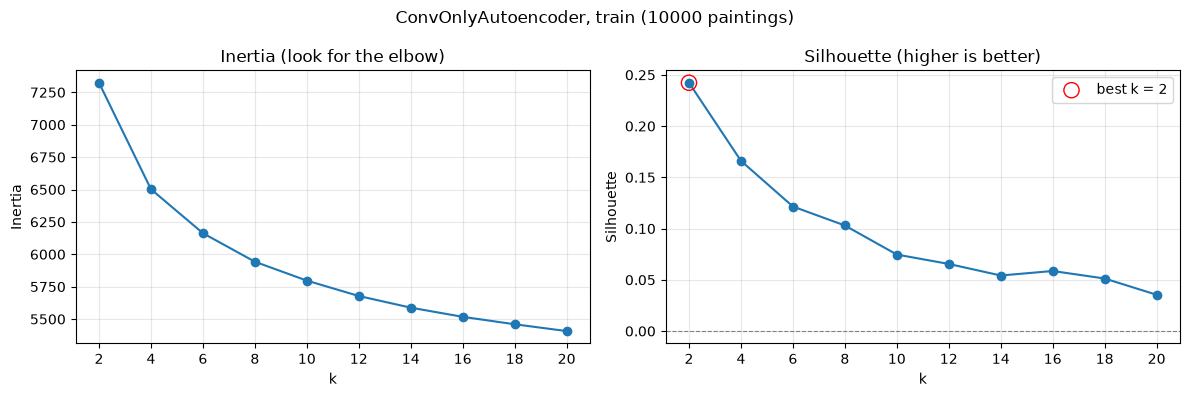

In [ ]:
sweep = kmeans_sweep(features, K_SWEEP, seed=SEED)
plot_kmeans_sweep(sweep, title=f"{RUN_NAME}, {CLUSTER_SPLIT} ({len(features)} paintings)")
plt.show()

c:\Users\MatG\Desktop\UniStuff\MAGI\Semestr II\UczenieNienadzorowane\Project\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


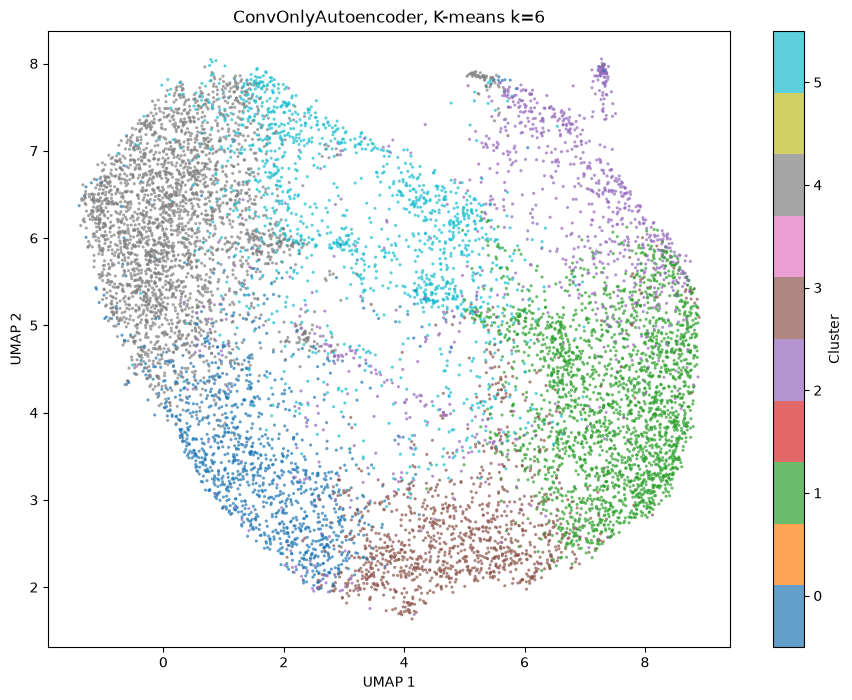

In [ ]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(features)
labels = kmeans.labels_

embedding_2d, idx_2d = umap_project(features, seed=SEED)
plot_clusters_2d(embedding_2d, labels[idx_2d], title=f"{RUN_NAME}, K-means k={K}")
plt.show()

# Evaluation

In [ ]:
silhouette = silhouette_score(features, labels, sample_size=min(10_000, len(labels)), random_state=SEED)
print(f"Silhouette (k={K}) = {silhouette:.3f} on {len(labels)} paintings")

rows = []
for column in LABEL_COLUMNS:
    known = meta[column].notna().to_numpy()          # preprocessing set some labels to None
    y_true, y_pred = meta[column][known].to_numpy(), labels[known]
    rows.append({
        "labels": column,
        "classes": len(np.unique(y_true)),
        "paintings": int(known.sum()),
        "NMI": normalized_mutual_info_score(y_true, y_pred),
        "AMI": adjusted_mutual_info_score(y_true, y_pred),
        "ARI": adjusted_rand_score(y_true, y_pred)
    })
display(pd.DataFrame(rows).round(3))

Silhouette (k=6) = 0.122 on 10000 paintings


,labels,classes,paintings,NMI,AMI,ARI
0,style,128,9998,0.055,0.043,0.010
1,genre,42,9998,0.065,0.061,0.035
2,artist,1550,9998,0.146,0.060,0.002


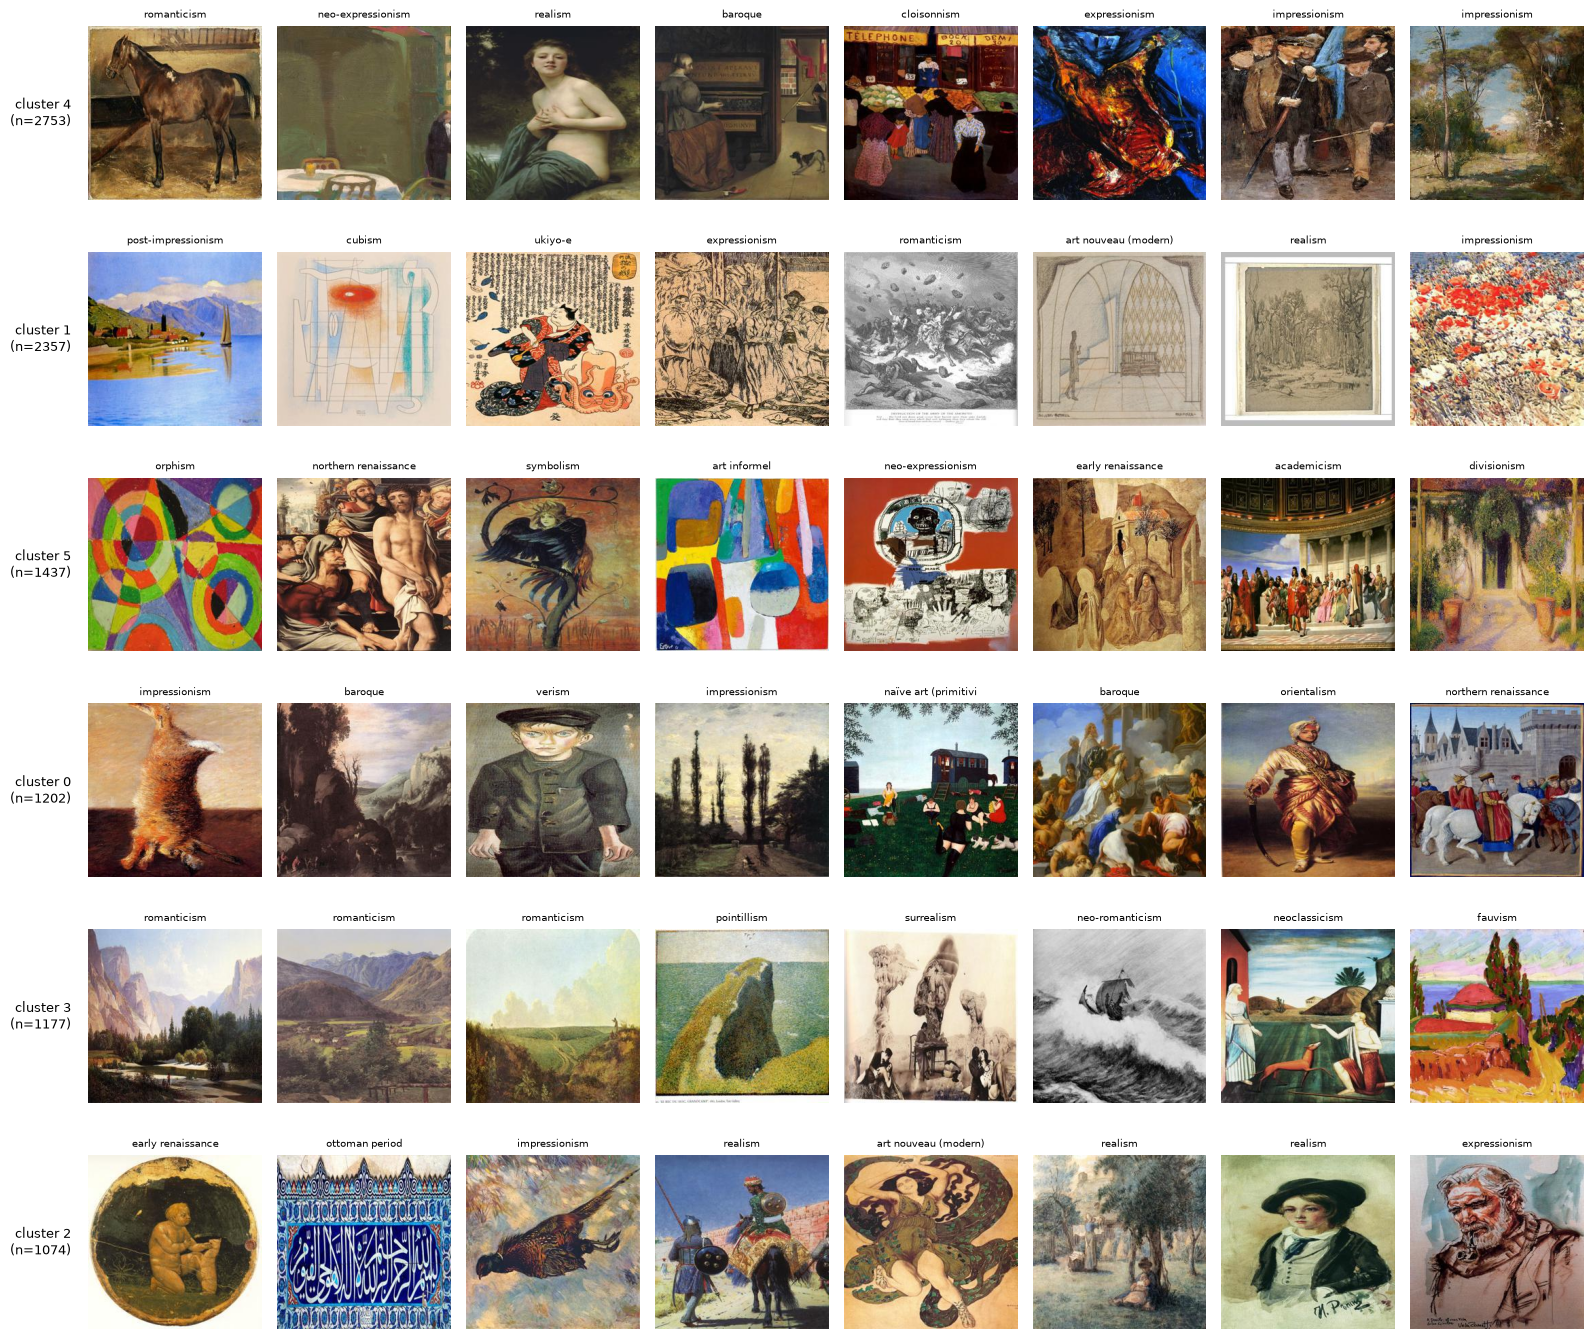

In [ ]:
plot_cluster_samples(ds_cluster, labels, n_per_cluster=8, captions=meta["style"], seed=SEED)

In [ ]:
# Embeddings in -> cluster labels out (preprocessing + K-means, fitted above)
if SAVE_CLUSTERER is not None:
    clusterer = make_pipeline(*[step for _, step in preprocess.steps], kmeans)
    Path(SAVE_CLUSTERER).parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(clusterer, SAVE_CLUSTERER)
    print(f"saved {SAVE_CLUSTERER}")

saved checkpoints\rgb_conv_only_kmeans6.joblib
